In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import pandas as pd
import cv2

In [3]:
dataset_dir=Path("C:/Users/SHIVAMANI/OneDrive/HTML/Deep Learning/AI-Medical-Image-Analysis/dataset")

In [4]:
TRAIN_DIR = dataset_dir / "train"
VAL_DIR = dataset_dir / "val"
TEST_DIR = dataset_dir / "test"

print("Train:",TRAIN_DIR)
print("Validation:",VAL_DIR)
print("Test:",TEST_DIR)


Train: C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\dataset\train
Validation: C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\dataset\val
Test: C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\dataset\test


In [5]:
print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())
print("Validation exists:", VAL_DIR.exists())

print("\nTrain classes:", os.listdir(TRAIN_DIR))
print("Test classes:", os.listdir(TEST_DIR))
print("Validation classes:", os.listdir(VAL_DIR))

Train exists: True
Test exists: True
Validation exists: True

Train classes: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']
Validation classes: ['NORMAL', 'PNEUMONIA']


In [6]:
data = []

for split, split_dir in [
    ("train", TRAIN_DIR),
    ("test", TEST_DIR),
    ("validation", VAL_DIR)
]:
    
    for label in ["NORMAL", "PNEUMONIA"]:
        
        class_dir = split_dir / label
        
        for image_path in class_dir.iterdir():
            
            if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                
                data.append({
                    "image_path": str(image_path),
                    "label": label,
                    "split": split
                })

df = pd.DataFrame(data)

print("Total images:", len(df))

Total images: 5856


In [7]:
df.head()

,image_path,label,split
0,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,NORMAL,train
1,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,NORMAL,train
2,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,NORMAL,train
3,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,NORMAL,train
4,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,NORMAL,train


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5856 entries, 0 to 5855
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image_path  5856 non-null   str  
 1   label       5856 non-null   str  
 2   split       5856 non-null   str  
dtypes: str(3)
memory usage: 137.4 KB


In [9]:
df.shape

(5856, 3)

In [10]:
df.isnull().sum()

image_path    0
label         0
split         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["image_path"].duplicated().sum()

np.int64(0)

In [13]:
df["label"].value_counts()

label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

In [14]:
pd.crosstab(df["split"], df["label"])

label,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
validation,8,8


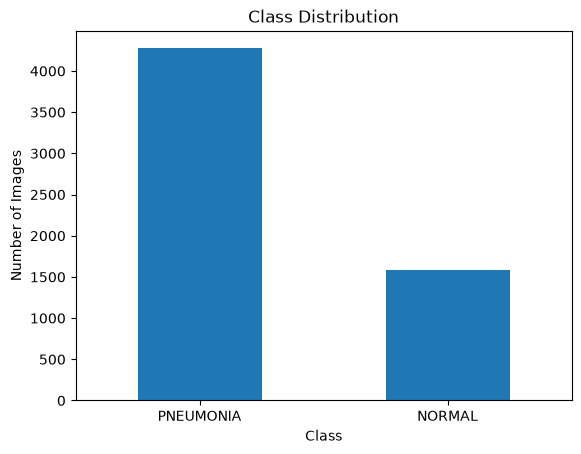

In [15]:
df["label"].value_counts().plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

In [16]:
sample_path = df.iloc[0]["image_path"]

image = cv2.imread(sample_path)

print("Image path:", sample_path)
print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image path: C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\dataset\train\NORMAL\IM-0115-0001.jpeg
Image shape: (1858, 2090, 3)
Image data type: uint8


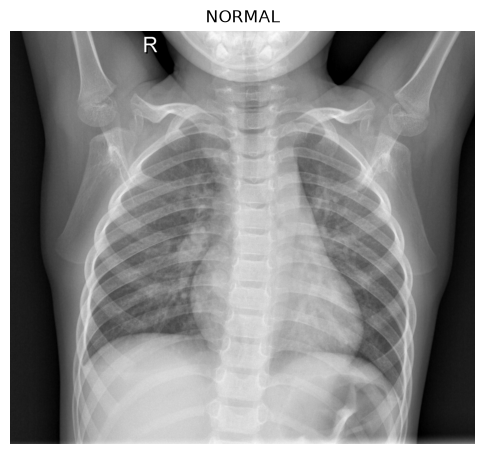

In [17]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title(df.iloc[0]["label"])
plt.axis("off")
plt.show()

In [18]:
image_info = []

for image_path in df["image_path"]:
    image = cv2.imread(image_path)

    if image is not None:
        height, width, channels = image.shape

        image_info.append({
            "image_path": image_path,
            "height": height,
            "width": width,
            "channels": channels
        })

image_info_df = pd.DataFrame(image_info)

print("Images successfully checked:", len(image_info_df))

Images successfully checked: 5856


In [19]:
image_info_df.head()

,image_path,height,width,channels
0,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,1858,2090,3
1,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,1152,1422,3
2,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,1434,1810,3
3,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,1279,1618,3
4,C:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning...,1125,1600,3


In [20]:
image_info_df[["height", "width", "channels"]].describe()

,height,width,channels
count,5856.000000,5856.000000,5856.0
mean,970.689037,1327.880806,3.0
std,383.392117,363.500922,0.0
min,127.000000,384.000000,3.0
25%,688.000000,1056.000000,3.0
50%,888.000000,1281.000000,3.0
75%,1187.000000,1560.000000,3.0
max,2713.000000,2916.000000,3.0


In [21]:
image_info_df["channels"].value_counts()

channels
3    5856
Name: count, dtype: int64

In [22]:
corrupted_images = []

for image_path in df["image_path"]:
    image = cv2.imread(image_path)

    if image is None:
        corrupted_images.append(image_path)

print("Corrupted/unreadable images:", len(corrupted_images))

Corrupted/unreadable images: 0


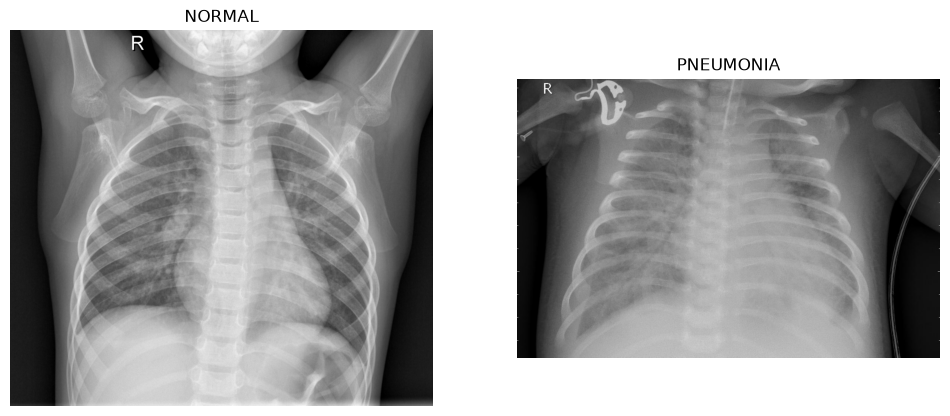

In [23]:
normal_image_path = df[df["label"] == "NORMAL"].iloc[0]["image_path"]
pneumonia_image_path = df[df["label"] == "PNEUMONIA"].iloc[0]["image_path"]

normal_image = cv2.imread(normal_image_path)
pneumonia_image = cv2.imread(pneumonia_image_path)

normal_image = cv2.cvtColor(normal_image, cv2.COLOR_BGR2RGB)
pneumonia_image = cv2.cvtColor(pneumonia_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(normal_image)
plt.title("NORMAL")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pneumonia_image)
plt.title("PNEUMONIA")
plt.axis("off")

plt.show()

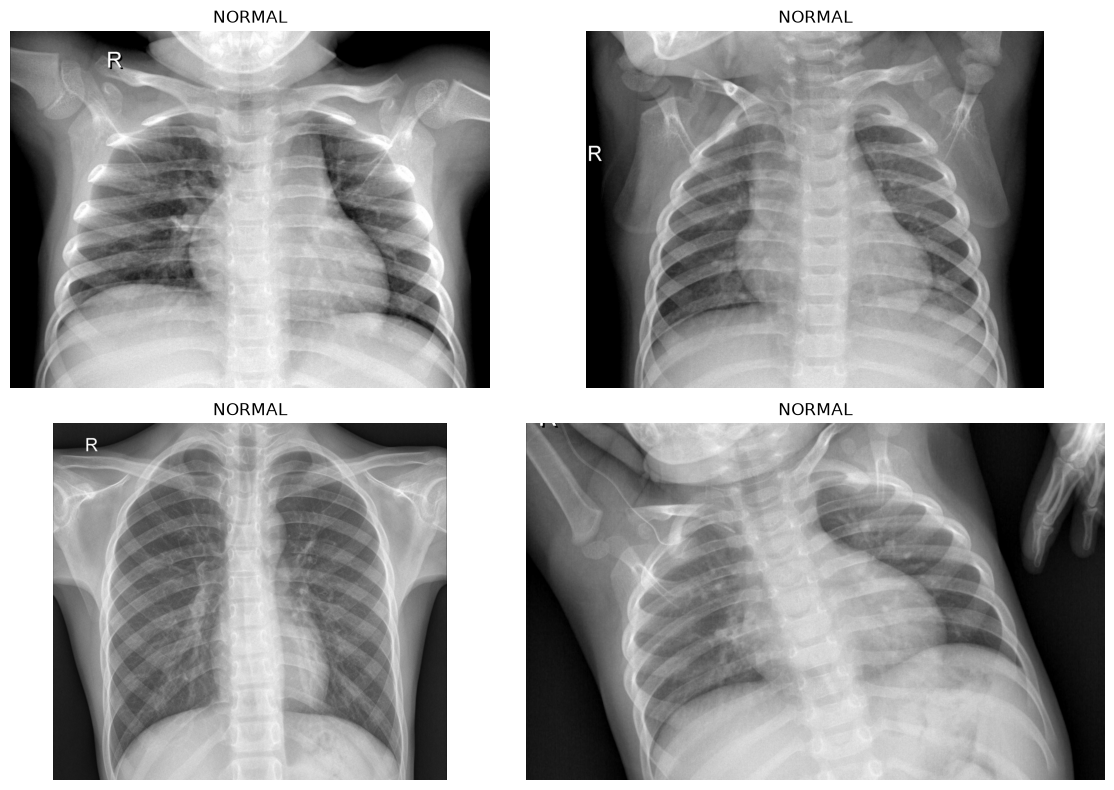

In [24]:
normal_samples = df[df["label"] == "NORMAL"].sample(4, random_state=42)

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(normal_samples.iterrows()):
    image = cv2.imread(row["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title("NORMAL")
    plt.axis("off")

plt.tight_layout()
plt.show()

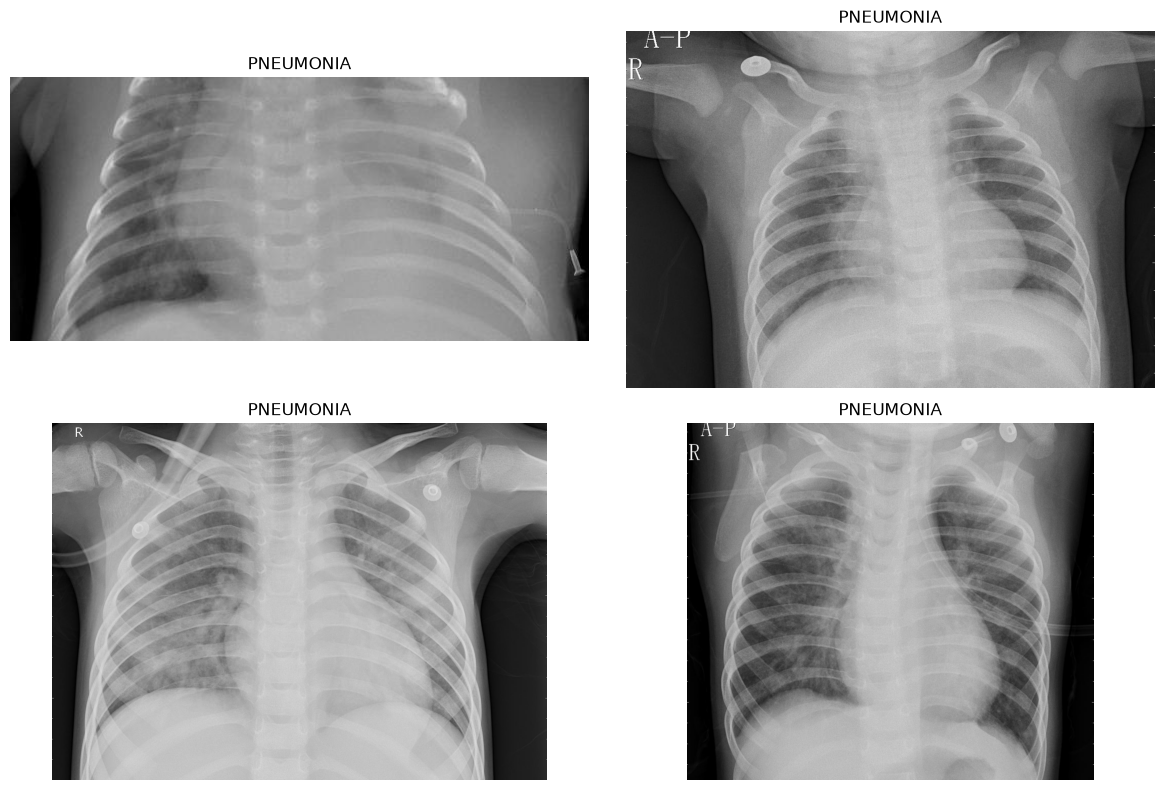

In [25]:
pneumonia_samples = df[df["label"] == "PNEUMONIA"].sample(4, random_state=42)

plt.figure(figsize=(12, 8))

for i, (_, row) in enumerate(pneumonia_samples.iterrows()):
    image = cv2.imread(row["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title("PNEUMONIA")
    plt.axis("off")

plt.tight_layout()
plt.show()

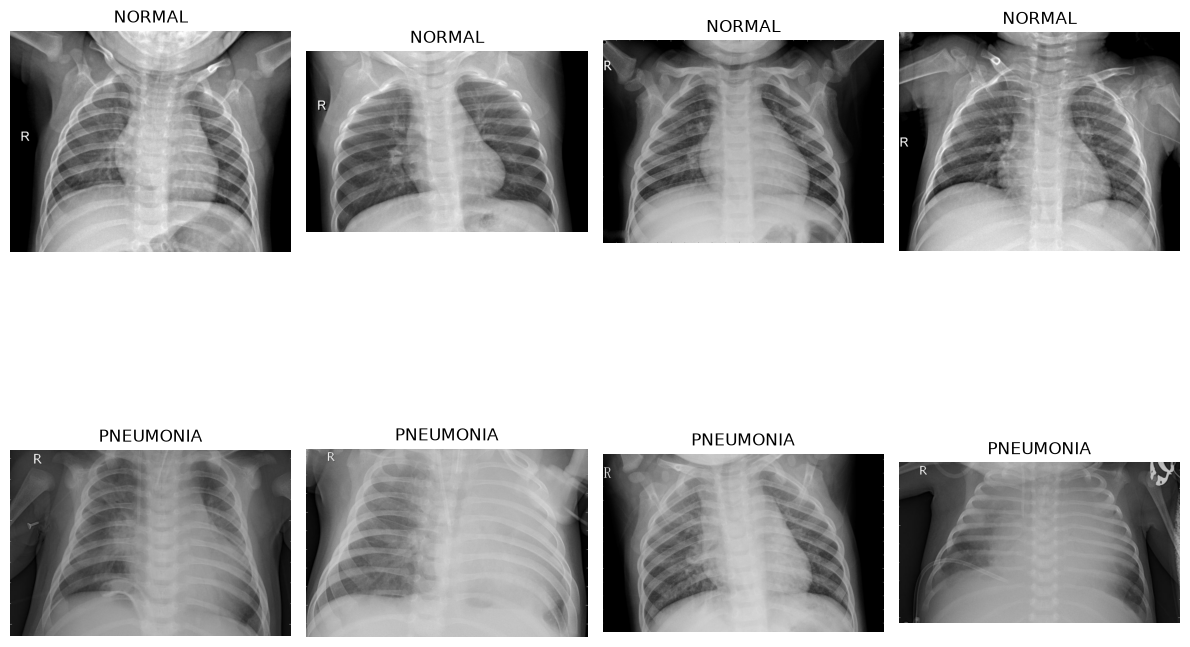

In [26]:
normal_samples = df[df["label"] == "NORMAL"].sample(4, random_state=10)
pneumonia_samples = df[df["label"] == "PNEUMONIA"].sample(4, random_state=10)

samples = pd.concat([normal_samples, pneumonia_samples])

plt.figure(figsize=(12, 10))

for i, (_, row) in enumerate(samples.iterrows()):
    image = cv2.imread(row["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(row["label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
sample_path = df.sample(1, random_state=42).iloc[0]["image_path"]

image = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

print("Minimum pixel value:", image.min())
print("Maximum pixel value:", image.max())
print("Mean pixel value:", image.mean())

Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 160.95334878516624


In [28]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [29]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

Found 5216 files belonging to 2 classes.


In [30]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)


Found 16 files belonging to 2 classes.


In [31]:
print("Classes:", train_ds.class_names)

Classes: ['NORMAL', 'PNEUMONIA']


In [32]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Image data type: <dtype: 'float32'>


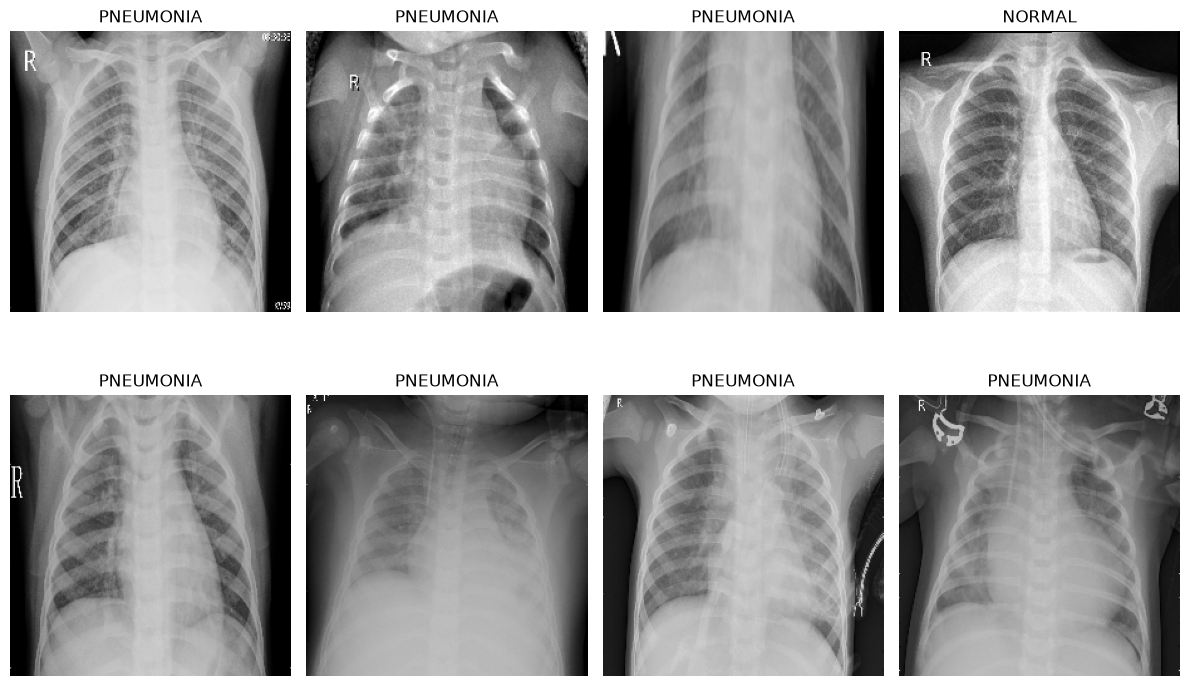

In [33]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title("PNEUMONIA" if labels[i].numpy()[0] == 1 else "NORMAL")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
import tensorflow as tf

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

In [35]:
train_df = df[df["split"] == "train"].copy()

train_paths = train_df["image_path"].values
train_labels = (train_df["label"] == "PNEUMONIA").astype(np.float32).values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_df),
    seed=42
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

print("Training images:", len(train_df))

Training images: 5216


In [36]:
val_df = df[df["split"] == "validation"].copy()

val_paths = val_df["image_path"].values
val_labels = (val_df["label"] == "PNEUMONIA").astype(np.float32).values

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Validation images:", len(val_df))

Validation images: 16


In [37]:
test_df = df[df["split"] == "test"].copy()

test_paths = test_df["image_path"].values
test_labels = (test_df["label"] == "PNEUMONIA").astype(np.float32).values

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test images:", len(test_df))

Test images: 624


In [38]:
from sklearn.model_selection import train_test_split

train_df = df[df["split"] == "train"].copy()

train_split_df, val_split_df = train_test_split(
    train_df,
    test_size=0.10,
    stratify=train_df["label"],
    random_state=42
)

print("New training images:", len(train_split_df))
print("New validation images:", len(val_split_df))

New training images: 4694
New validation images: 522


In [39]:
print("Training distribution:")
print(train_split_df["label"].value_counts())

print("\nValidation distribution:")
print(val_split_df["label"].value_counts())

Training distribution:
label
PNEUMONIA    3487
NORMAL       1207
Name: count, dtype: int64

Validation distribution:
label
PNEUMONIA    388
NORMAL       134
Name: count, dtype: int64


In [40]:
train_paths = train_split_df["image_path"].values

train_labels = (
    train_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_split_df),
    seed=42
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

print("Training images:", len(train_split_df))

Training images: 4694


In [41]:
val_paths = val_split_df["image_path"].values

val_labels = (
    val_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

print("Validation images:", len(val_split_df))

Validation images: 522


In [42]:
from sklearn.model_selection import train_test_split

train_df = df[df["split"] == "train"].copy()

train_split_df, val_split_df = train_test_split(
    train_df,
    test_size=0.10,
    stratify=train_df["label"],
    random_state=42
)

print("New training images:", len(train_split_df))
print("New validation images:", len(val_split_df))

print("\nTraining distribution:")
print(train_split_df["label"].value_counts())

print("\nValidation distribution:")
print(val_split_df["label"].value_counts())


New training images: 4694
New validation images: 522

Training distribution:
label
PNEUMONIA    3487
NORMAL       1207
Name: count, dtype: int64

Validation distribution:
label
PNEUMONIA    388
NORMAL       134
Name: count, dtype: int64


In [43]:
train_paths = train_split_df["image_path"].values

train_labels = (
    train_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_split_df),
    seed=42
)

train_ds = train_ds.batch(BATCH_SIZE)

train_ds = train_ds.prefetch(
    tf.data.AUTOTUNE
)

print("Training images:", len(train_split_df))

Training images: 4694


In [44]:
val_paths = val_split_df["image_path"].values

val_labels = (
    val_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)

val_ds = val_ds.prefetch(
    tf.data.AUTOTUNE
)

print("Validation images:", len(val_split_df))

Validation images: 522


In [45]:
for images, labels in train_ds.take(1):
    print("Training image shape:", images.shape)
    print("Training label shape:", labels.shape)

Training image shape: (32, 224, 224, 3)
Training label shape: (32,)


In [46]:
for images, labels in val_ds.take(1):
    print("Validation image shape:", images.shape)
    print("Validation label shape:", labels.shape)
    

Validation image shape: (32, 224, 224, 3)
Validation label shape: (32,)


In [47]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

In [48]:
normalization = layers.Rescaling(1./255)

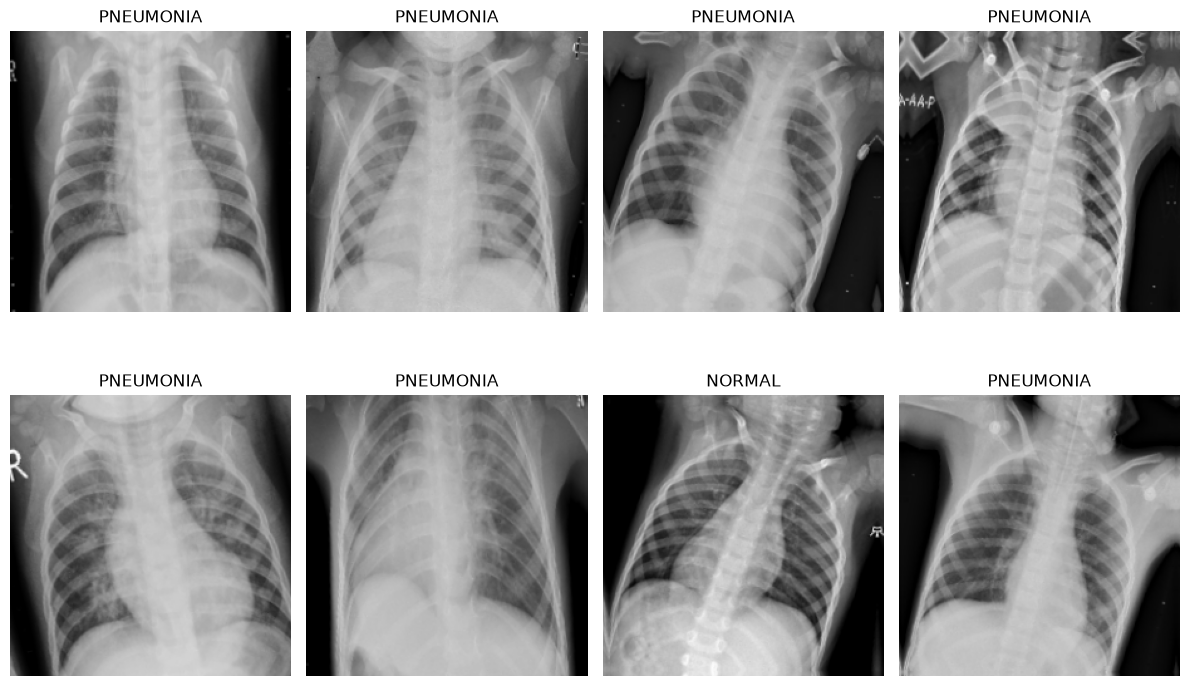

In [49]:
for images, labels in train_ds.take(1):
    augmented_images = data_augmentation(images)

    plt.figure(figsize=(12, 8))

    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(
            augmented_images[i].numpy().astype("uint8")
        )
        plt.title(
            "PNEUMONIA"
            if labels[i].numpy() == 1
            else "NORMAL"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [50]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("Base model loaded.")

Base model loaded.


In [51]:
from tensorflow.keras import Model

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = normalization(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [52]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    0: class_weights_array[0],
    1: class_weights_array[1]
}

print("Class weights:")
print(class_weights)

Class weights:
{0: np.float64(1.944490472245236), 1: np.float64(0.6730714080871809)}


In [53]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [54]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "../models/best_mobilenetv2.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Callbacks created.")

Callbacks created.


In [55]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/10


c:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


147/147 ━━━━━━━━━━━━━━━━━━━━ 40s 225ms/step - accuracy: 0.5816 - loss: 0.6962 - precision: 0.7928 - recall: 0.5913 - val_accuracy: 0.7644 - val_loss: 0.5431 - val_precision: 0.9288 - val_recall: 0.7397
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 36s 221ms/step - accuracy: 0.7603 - loss: 0.5100 - precision: 0.9009 - recall: 0.7611 - val_accuracy: 0.8008 - val_loss: 0.4546 - val_precision: 0.9733 - val_recall: 0.7526
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 35s 213ms/step - accuracy: 0.8102 - loss: 0.4286 - precision: 0.9321 - recall: 0.8030 - val_accuracy: 0.8448 - val_loss: 0.3878 - val_precision: 0.9782 - val_recall: 0.8093
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 35s 216ms/step - accuracy: 0.8402 - loss: 0.3749 - precision: 0.9462 - recall: 0.8322 - val_accuracy: 0.8582 - val_loss: 0.3470 - val_precision: 0.9758 - val_recall: 0.8299
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 34s 210ms/step - accuracy: 0.8577 - loss: 0.3308 - precision: 0.9575 - recall: 0.8460 - val_accuracy: 0.8716 - val_loss

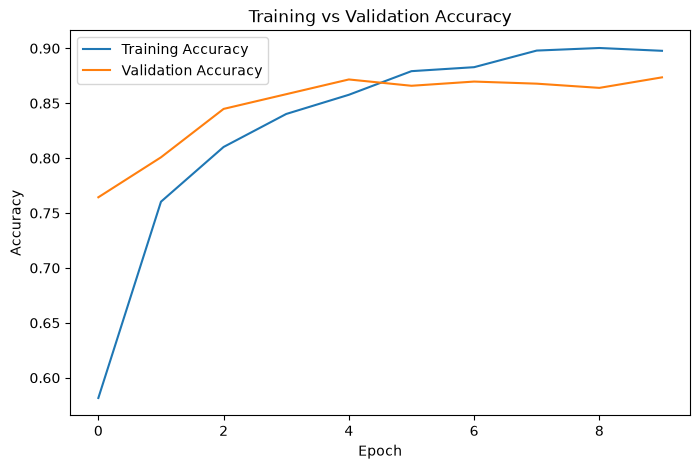

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

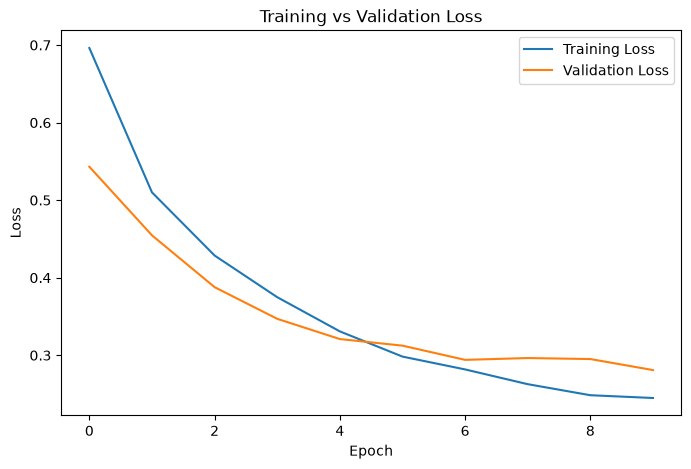

In [57]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Evaluation on Testing data

In [58]:
test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\nTest Results:")
for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 186ms/step - accuracy: 0.8814 - loss: 0.3215 - precision: 0.9115 - recall: 0.8974

Test Results:
loss: 0.3215
compile_metrics: 0.8814


In [59]:
y_true = []
y_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_prob.extend(predictions.flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:", len(y_true))
print("Predictions:", len(y_pred))

Actual labels: 624
Predictions: 624


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.8814
Precision: 0.9115
Recall   : 0.8974
F1 Score : 0.9044
ROC-AUC  : 0.9408


In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

print(cm)

[[200  34]
 [ 40 350]]


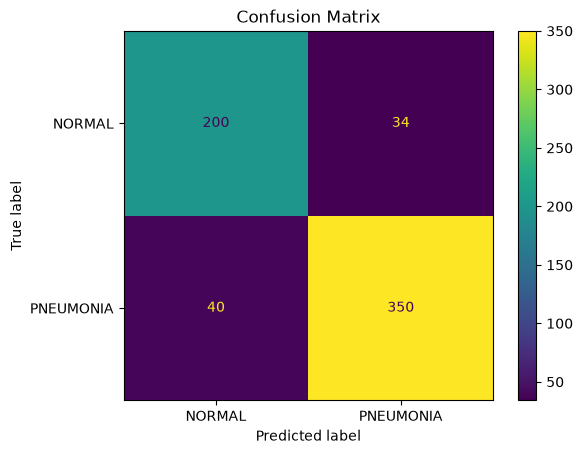

In [62]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [63]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.83      0.85      0.84       234
   PNEUMONIA       0.91      0.90      0.90       390

    accuracy                           0.88       624
   macro avg       0.87      0.88      0.87       624
weighted avg       0.88      0.88      0.88       624



In [64]:
model.save("../models/mobilenetv2_baseline.keras")

In [65]:
import os

print(
    "Baseline model saved:",
    os.path.exists("../models/mobilenetv2_baseline.keras")
)

Baseline model saved: True


In [66]:
import os

os.makedirs("../models", exist_ok=True)

model.save("../models/mobilenetv2_baseline.keras")

print("Baseline model saved successfully!")
print(
    "File exists:",
    os.path.exists("../models/mobilenetv2_baseline.keras")
)

Baseline model saved successfully!
File exists: True


In [67]:
model.save("../models/mobilenetv2_baseline.keras")

In [68]:
import os

os.makedirs("../results", exist_ok=True)

train_split_df.to_csv("../results/train_split.csv", index=False)
val_split_df.to_csv("../results/val_split.csv", index=False)
test_df.to_csv("../results/test_split.csv", index=False)

print("Dataset splits saved successfully!")

Dataset splits saved successfully!
